<font face="Times New Roman" size=5>
<div dir=rtl align="center">
<font face="Times New Roman" size=5>
In The Name of God
</font>
<br>
<img src="https://logoyar.com/content/wp-content/uploads/2021/04/sharif-university-logo.png" alt="University Logo" width="150" height="150">
<br>
<font face="Times New Roman" size=4 align=center>
Sharif University of Technology - Department of Electrical Engineering
</font>
<br>
<font color="#008080" size=6>
Deep Generative Models
</font>
<hr/>
<font color="#800080" size=5>
Assignment 1 : Deep Autoregressive Models
<br>
</font>
<font size=5>
Instructor: Dr. S. Amini
<br>
</font>
<font size=4>
Fall 2025
<br>
</font>
<font face="Times New Roman" size=4>
</font>
<hr>
<font color='red'  size=4>
<br>
</font>
<font face="Times New Roman" size=4 align=center>
Feel free to ask your questions in Telegram : @imoonamm
</font>
<br>
<hr>
</div></font>

**You should only change the blank sections, marked with TODO**

Pay attention to docstrings, as they may drastically help with your implementation.

You are advised to read all related papers and material, to help you better understand the design of each model.

# Question 1: WaveNet : A generative model for raw audio

WaveNet is a general purpose technology that has allowed us to unlock a range of new applications, from improving video calls on even the weakest connections to helping people regain their original voice after losing the ability to speak.

![Local GIF](unnamed.gif)

WaveNet models raw audio waveforms autoregressively:
$
p(x_{1:T}) = \prod_{t=1}^T p(x_t \mid x_{<t})
$
\
Instead of predicting spectrograms or using a vocoder, WaveNet predicts the next audio sample directly (often after µ-law companding and 8-bit/256-way quantization). This yields very natural sounding speech and music because the network learns the waveform structure end-to-end.

## 2. Core

### 2.1 Causal convolutions
A causal 1D convolution ensures predictions at time \(t\) don't depend on future samples:
- Achieved by padding only on the left (past).
- In practice, use `padding = dilation * (kernel_size - 1)` and then trim the rightmost elements (or use `Chomp1d` cropping).

### 2.2 Dilated convolutions
Dilations `[1, 2, 4, 8, ...]` in stacked layers let the receptive field grow exponentially with depth while keeping the number of parameters manageable. A stack of several cycles of dilations covers long temporal context (hundreds to thousands of samples).

### 2.3 Gated activation units
Each residual block uses a gated unit:
$
\text{z} = \tanh(W_f * x) \odot \sigma(W_g * x)
$
where `*` is dilated causal conv, `W_f` and `W_g` are convolution filters. The output splits to (1) residual connection and (2) skip connection that is added to final output.

### 2.4 Residual & skip connections
- Residual: `x_{l+1} = x_l + \text{residual\_out}` to ease training.
- Skip: every block outputs a skip tensor; all skip outputs are summed, then passed through post-processing (ReLU, Conv, softmax) to produce the final distribution over quantized samples.

### 2.5 Output quantization / softmax
Audio samples are often µ-law quantized to 256 values; WaveNet predicts a categorical distribution (`softmax(256)`) over those values for each time step. Continuous outputs are also possible (mixture of logistics / Gaussians) but discrete softmax is standard in the original paper.

### 2.6 Conditioning
- **Global conditioning**: a per-utterance vector (e.g., speaker id embedding) is added to layer activations.
- **Local conditioning**: low-rate features (e.g., mel spectrogram) are upsampled (transposed conv / nearest) and added at each time step.

---

## 3. Training & sampling

### Training
- Teacher forcing: at training time the network receives true previous samples and learns to predict the next sample with cross-entropy loss (if quantized).
- Batch size and optimization: use Adam, gradient clipping recommended for stability.
- Preprocess: µ-law companding + 256-level quantization is common.

### Sampling (inference)
- Autoregressive generation: sample one sample at a time and feed it back.
- Slow by default — many acceleration techniques exist (distillation → Parallel Wavenet, caching convolutions, WaveRNN, etc.).



**Reference:** [WaveNet: A Generative Model for Raw Audio* (van den Oord et al., DeepMind, 2016)](https://arxiv.org/abs/1609.03499)


In [26]:
# !pip install torchaudio
import torchaudio
import os

In [27]:
import numpy as np
from matplotlib import pyplot as plt
import torch
from torch import nn
from torch.nn import ModuleList
from IPython.display import Audio
from torch.autograd import Variable
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using {} device".format(device))

Using cuda device


### at first you must convert input into One Hot vector

5 Points


In [28]:
import torch.nn.functional as F

class OneHot(nn.Module):
    def __init__(self, MU):
        super(OneHot, self).__init__()
        self.MU = MU

    def forward(self, x):
        x = x.long()
        device = x.device
        oh = F.one_hot(x, num_classes=self.MU).permute(0, 2, 1).float().to(device)
        return oh

    def __repr__(self):
        return f"{self.__class__.__name__}({self.MU})"

Before diving into the WaveNet model itself, it’s important to understand what kind of **data** we are modeling — **raw audio waveforms**.  
Neural networks can only process numbers, so we need to represent sound in a numerical form that captures its essential structure and variation.

---

## 1. Sampling Rate and Bit Depth

### Sound as a Signal
Sound in the real world is a **continuous analog waveform** — a pressure signal that varies smoothly over time.  
To process it digitally, we **sample** it: we take discrete measurements of the amplitude at equally spaced time intervals.

This process converts a continuous signal into a **time series of numbers**:
$
x = [x_1, x_2, \dots, x_T]
$
where each \(x_t\) represents the air pressure (or voltage) at time step \(t\).

---

### Sampling Rate
The **sampling rate** defines **how many times per second** we measure the amplitude of the signal.  
Typical values:
- CD quality audio: 44,100 Hz (samples per second)
- Speech datasets: 16,000 Hz or 22,050 Hz

A higher sampling rate means more detail, but also more data to process.  
WaveNet typically models 16 kHz or 22 kHz audio for speech generation tasks.

---

### Bit Depth
Each recorded sample must be represented by a finite number of bits.  
The **bit depth** determines the range and precision of these values:
- 8-bit → 256 possible levels  
- 16-bit → 65,536 levels  
- 24-bit → 16,777,216 levels  

The bit depth affects the **signal-to-noise ratio (SNR)** — higher bit depth means less quantization noise and a larger dynamic range:
$
\text{SNR} \approx 6.02 \times \text{bit depth} + 1.76\ \text{dB}
$

For example:
- 8-bit ≈ 49.9 dB SNR  
- 16-bit ≈ 98 dB SNR

---

## 2. From Audio to Time Series

After digitization, the audio signal becomes a **sequence of numbers over time**, also known as a **time series**.  
Each point depends on previous ones — this temporal dependency is what WaveNet models autoregressively:
$
p(x_{1:T}) = \prod_{t=1}^{T} p(x_t \mid x_{<t})
$

However, raw 16-bit audio contains **too many values** (65,536 possible amplitudes).  
Predicting the exact next value among that huge range is extremely hard for a neural network.

To simplify, we reduce this dynamic range to a smaller set — typically **256 levels** — using a technique called **µ-law companding**.

---

## 3. µ-law Quantization (Companding Transformation)

### Motivation
Human hearing follows the **Weber–Fechner law** — our perception of changes in loudness is **logarithmic**, not linear.  
That means we are more sensitive to small amplitude changes in quiet sounds than in loud ones.

µ-law companding exploits this property by **compressing the amplitude range logarithmically** —  
it allocates more resolution to small signals (quiet sounds) and less to large ones.

---

### µ-law Formula

$
f(x) = \text{sign}(x) \cdot \frac{\ln(1 + \mu |x|)}{\ln(1 + \mu)}, \quad -1 \le x \le 1
$

where:
- \(x\) = input waveform (normalized to [-1, 1])  
- \(\mu\) = companding constant (usually 255 for 8-bit quantization)

After applying µ-law, we map the range \([-1, 1]\) to discrete integer values \([0, 255]\).

---


## Defining Wavenet

20 Points

The following figure describes the overall architecture of WaveNet. Note that Transformers were non-existent in 2016!

![Wavenet Arch](WaveNet.png)

In [29]:
import torch

class Wavenet(nn.Module):
    def __init__(self, dilation_depth, n_blocks, n_dil_channnels, n_residual_channels,n_skip_channels, n_category, kernel_size):
        super(Wavenet,self).__init__()
        self.dilation_depth = dilation_depth
        self.n_blocks = n_blocks
        self.n_dil_channnels = n_dil_channnels
        self.n_residual_channels = n_residual_channels
        self.n_skip_channels = n_skip_channels
        self.n_category = n_category
        self.kernel_size = kernel_size
        self.One_hot = OneHot(n_category)

        ###Building the model###
        self.initial_conv = nn.Conv1d(n_category, n_residual_channels, 1)

        self.dilations = [2**i for i in range(dilation_depth)] * n_blocks
        self.receptive_field = 1 + sum(d * (kernel_size - 1) for d in self.dilations)

        self.filter_conv = ModuleList()
        self.gate_conv = ModuleList()
        self.skip_conv = ModuleList()
        self.residual_conv = ModuleList()

        for dilation in self.dilations:
            self.filter_conv.append(nn.Conv1d(n_residual_channels, n_dil_channnels, kernel_size, dilation=dilation))
            self.gate_conv.append(nn.Conv1d(n_residual_channels, n_dil_channnels, kernel_size, dilation=dilation))
            self.skip_conv.append(nn.Conv1d(n_dil_channnels, n_skip_channels, 1))
            self.residual_conv.append(nn.Conv1d(n_dil_channnels, n_residual_channels, 1))

        self.post_conv1 = nn.Conv1d(n_skip_channels, n_skip_channels, 1)
        self.post_conv2 = nn.Conv1d(n_skip_channels, n_category, 1)

    def forward(self, x):
        x = self.One_hot(x)
        x = self.initial_conv(x)

        x_skip = 0
        for k, dilation in enumerate(self.dilations):
            x_residual = x
            padding_amount = dilation * (self.kernel_size - 1)
            x_padded = F.pad(x, (padding_amount, 0))

            x = torch.tanh(self.filter_conv[k](x_padded)) * torch.sigmoid(self.gate_conv[k](x_padded))

            x_skip = x_skip + self.skip_conv[k](x)

            residual_out = self.residual_conv[k](x)
            x = residual_out + x_residual

        burn_in = self.receptive_field - 1
        x_skip = x_skip[:, :, burn_in:]
            
        x = F.relu(x_skip)
        x = F.relu(self.post_conv1(x))
        x = self.post_conv2(x)
        return x

    def generate(self, input, num_samples=100):
        gen_list = input.tolist() if isinstance(input, torch.Tensor) else list(input)
        current_context = gen_list[-self.receptive_field:]

        self.eval()
        with torch.no_grad():
            for _ in range(num_samples):
                input_tensor = torch.LongTensor(current_context).unsqueeze(0).to(device)
                logits = self.forward(input_tensor)
                last_logits = logits[:, :, -1]
                s = F.softmax(last_logits, dim=1).squeeze(0)
                sampled_index = torch.multinomial(s, 1).item()
                gen_list.append(sampled_index)
                current_context = current_context[1:] + [sampled_index]

        return gen_list

Quantization of 16 bit audio

5 Points

In [30]:
def mulaw_quantize(x, qc):
    mu = torch.tensor(qc - 1, dtype=x.dtype, device=x.device)
    x_mu = torch.sign(x) * torch.log(1 + mu * torch.abs(x)) / torch.log(1 + mu)
    x_mu = ((x_mu + 1) / 2 * mu).long()
    x_mu = torch.clamp(x_mu, 0, mu)
    return x_mu

Inverse quantization

5 Points

In [31]:
def inv_mulaw_quantize(x_mu, quantization_channels=256, device = device):
    x_mu_normalized = x_mu.float().to(device) / (quantization_channels - 1)
    x_mu_mapped = 2 * x_mu_normalized - 1

    mu = quantization_channels - 1
    mu_plus_one_tensor = torch.tensor(1.0 + mu, device=x_mu_mapped.device)
    x = torch.sign(x_mu_mapped) * (1.0/mu) * (torch.pow(mu_plus_one_tensor, torch.abs(x_mu_mapped)) - 1)

    return x

## Load Dataset
In this part you must load the audio_dataset.npz that exist in zip file of homework

10 Points

In [32]:
import os
import os.path
import math
import threading
import torch
import torch.utils.data
import numpy as np
import librosa as lr
import bisect


class WavenetDataset(torch.utils.data.Dataset):
    def __init__(self,
                 dataset_file,
                 item_length,
                 target_length,
                 file_location=None,
                 classes=256,
                 sampling_rate=16000,
                 mono=True,
                 normalize=True,
                 dtype=np.uint8,
                 train=True,
                 test_stride=100):

        #               |----receptive_field----|
        #                                         |--output_length--|
        # example:  | | | | | | | | | | | | | | | | | | | | |
        # target:                                 | | | | | | | | | |
        #
        # item_length = receptive_field + output_length - 1

        self.dataset_file = dataset_file
        self._item_length = item_length
        self._test_stride = test_stride
        self.target_length = target_length
        self.classes = classes
        self.train = train

        if not os.path.isfile(dataset_file):
            assert file_location is not None, "no location for dataset files specified"
            self.mono = mono
            self.normalize = normalize
            self.sampling_rate = sampling_rate
            self.dtype = dtype
            self.create_dataset(file_location, dataset_file)

        self.data = np.load(self.dataset_file, mmap_mode='r')
        self.start_samples = [0]
        self._length = 0
        self.calculate_length()
        print("one hot input")

    def calculate_length(self):
        start_samples = [0]
        for i in range(len(self.data.keys())):
            start_samples.append(start_samples[-1] + len(self.data['arr_' + str(i)]))
        available_length = start_samples[-1] - (self._item_length - (self.target_length - 1)) - 1
        self._length = math.floor(available_length / self.target_length)
        self.start_samples = start_samples


    def set_item_length(self, l):
        self._item_length = l
        self.calculate_length()

    def __getitem__(self, idx):
        if self.train:
            idx += idx // (self._test_stride - 1)
        else:
            idx *= self._test_stride

        if idx >= self._length:
             raise IndexError("Index out of range")

        start_index = idx * self.target_length
        file_index = bisect.bisect_right(self.start_samples, start_index) - 1
        position_in_file = start_index - self.start_samples[file_index]

        current_file_data = self.data['arr_' + str(file_index)]

        item = current_file_data[position_in_file : position_in_file + self._item_length]

        input_sequence = torch.from_numpy(item[:-1]).long()
        target_sequence = torch.from_numpy(item[-self.target_length:]).long()

        return input_sequence, target_sequence

    def __len__(self):
        test_length = math.floor(self._length / self._test_stride) if self._test_stride > 0 else 0
        if self.train:
            return self._length - test_length
        else:
            return test_length

def quantize_data(data, classes):
    mu = classes - 1
    mu_x = mu_law_encoding(data, mu)
    quantized = ((mu_x + 1) / 2 * mu + 0.5).astype(np.int64)
    return quantized


def list_all_audio_files(location):
    audio_files = []
    for dirpath, _, filenames in os.walk(location):
        for filename in filenames:
            if filename.lower().endswith(('.wav', '.mp3', '.flac')):
                audio_files.append(os.path.join(dirpath, filename))
    return audio_files


def mu_law_encoding(data, mu):
    mu = float(mu)
    mu_x = np.sign(data) * np.log1p(mu * np.abs(data)) / np.log1p(mu)
    return mu_x


def mu_law_expansion(data, mu):
    mu = float(mu)
    s = np.sign(data) * (1 / mu) * (np.power(1 + mu, np.abs(data)) - 1)
    return s

In [33]:
dilation_depth = 10
n_blocks = 2
n_dilation_channels = 24
n_residual_channels = 24
n_skip_channels = 128
n_category = 256
kernel_size = 2
model = Wavenet(dilation_depth,n_blocks,n_dilation_channels ,n_residual_channels,n_skip_channels,n_category,kernel_size)
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {count_parameters(model):,} trainable parameters')
model.to(device)

The model has 178,744 trainable parameters


Wavenet(
  (One_hot): OneHot(256)
  (initial_conv): Conv1d(256, 24, kernel_size=(1,), stride=(1,))
  (filter_conv): ModuleList(
    (0): Conv1d(24, 24, kernel_size=(2,), stride=(1,))
    (1): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(2,))
    (2): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(4,))
    (3): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(8,))
    (4): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(16,))
    (5): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(32,))
    (6): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(64,))
    (7): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(128,))
    (8): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(256,))
    (9): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(512,))
    (10): Conv1d(24, 24, kernel_size=(2,), stride=(1,))
    (11): Conv1d(24, 24, kernel_size=(2,), stride=(1,), dilation=(2,))
    (12): Conv1d(24, 24, kernel_size=(2,), stride=(

### Define data generator

10 Points


In [34]:
def data_generation(data, fr, seq_len_segment , mu, device = device):
    batch_size, seq_len = data.shape
    start_indices = torch.randint(0,
                                  seq_len - seq_len_segment,
                                   (batch_size,),
                                  device=device)

    segments = []
    for i in range(batch_size):
        start = start_indices[i]
        end = start + seq_len_segment
        segments.append(data[i, start:end])

    processed_data = torch.stack(segments, dim=0)
    mu_encoded_data = mulaw_quantize(processed_data, mu)

    return mu_encoded_data

### Visualize sample of data

5 Points

one hot input


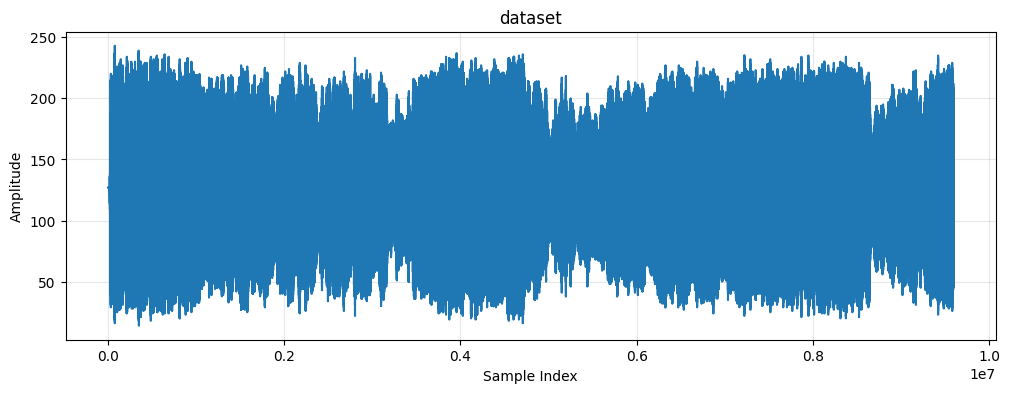

In [38]:
from IPython.display import Audio

target_legnth = 2048
item_legnth = model.receptive_field + target_legnth
# DATASET_FILE = '/content/drive/MyDrive/Colab Notebooks/DGM/audio_dataset.npz'
DATASET_FILE = '/kaggle/input/audio-dgm1/audio_dataset.npz'


dataset = WavenetDataset(
    dataset_file=DATASET_FILE,
    item_length=item_legnth,
    target_length=target_legnth,
    train=True)

waveform = dataset.data['arr_0']

plt.figure(figsize=(12, 4))
plt.plot(waveform)
plt.title('dataset')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.grid(alpha=0.3)
plt.show()

fs = 16000
Audio(waveform[:fs*20], rate=fs)

### Optimizer and Loss Function

5 Points

In [36]:
from torch.optim import Adam
model.to(device)
optimizer = Adam(params=model.parameters(), lr=0.001, eps=1e-8)
loss_function = nn.CrossEntropyLoss()

## Training

10 Points

In [39]:
from tqdm import tqdm

train_loader = torch.utils.data.DataLoader(
    dataset=dataset,
    batch_size=64,
    shuffle=True,
    pin_memory=True
)

print(f"device: {device}")

training_loss = []
epochs = 20

model.train()
for epoch in range(epochs):
    sum_losses = 0.0
    num_batches = 0

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{epochs}]")
    for input_data, target_data in loop:
        optimizer.zero_grad()

        input_data = input_data.to(device)
        target_data = target_data.to(device)

        output_logits = model(input_data)
        loss = loss_function(output_logits, target_data)

        loss.backward()
        optimizer.step()

        sum_losses += loss.item()
        num_batches += 1

        loop.set_postfix(loss=f"{loss.item():.6f}")

    epoch_loss = sum_losses / num_batches if num_batches > 0 else 0
    training_loss.append(epoch_loss)
    print(f"Epoch Loss: {epoch_loss:.6f}")

device: cuda


Epoch [1/20]: 100%|██████████| 73/73 [01:24<00:00,  1.16s/it, loss=4.806489]


Epoch Loss: 5.097416


Epoch [2/20]: 100%|██████████| 73/73 [01:24<00:00,  1.16s/it, loss=3.667826]


Epoch Loss: 4.143952


Epoch [3/20]: 100%|██████████| 73/73 [01:24<00:00,  1.16s/it, loss=3.569041]


... (31 outputs left out)

Epoch [19/20]: 100%|██████████| 73/73 [01:25<00:00,  1.17s/it, loss=3.142044]


Epoch Loss: 3.116254


Epoch [20/20]: 100%|██████████| 73/73 [01:25<00:00,  1.17s/it, loss=3.134429]

Epoch Loss: 3.107652


## Plot losses

5 Points

Text(0, 0.5, 'Loss')

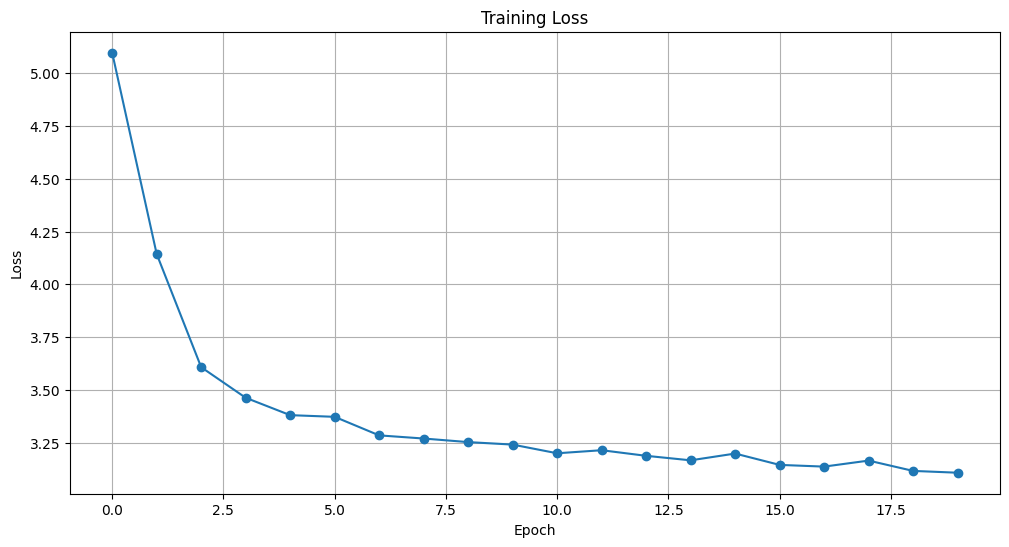

In [40]:
plt.figure(figsize=(12,6))
plt.plot(training_loss, marker='o')
plt.grid()
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

## Save the model

5 Points


In [41]:
torch.save(model.state_dict(), '/kaggle/working/wavenet_model.pth')
print(f"Model saved successfully to: /kaggle/working/wavenet_model.pth")

Model saved successfully to: /kaggle/working/wavenet_model.pth


## Generate Audio using trained model

5 Points

In [42]:
from IPython.display import Audio

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

dilation_depth = 10
n_blocks = 2
n_dilation_channels = 24
n_residual_channels = 24
n_skip_channels = 128
n_category = 256
kernel_size = 2
model = Wavenet(dilation_depth,n_blocks,n_dilation_channels ,n_residual_channels,n_skip_channels,n_category,kernel_size)

state_dict = torch.load('/kaggle/working/wavenet_model.pth', map_location=device)
model.load_state_dict(state_dict)
model.to(device)

input = torch.tensor([n_category // 2] * model.receptive_field ).to(device)

fs = 16000
waveform_data = model.generate(input, 10*fs) # 10s output
waveform = torch.tensor(waveform_data)
waveform = inv_mulaw_quantize(waveform, device=device).cpu().numpy()
Audio(waveform, rate=fs)